In [2]:
import pandas as np
from Bio.Seq import Seq
from Bio import Align
import re



# Barcode Base content

In [3]:
BC1 = "aacacagcgcgtatgcactgttgtcggagtataccc"
BC2 = "ctcaagcatcgatcatacctccaccaatgagccaga"
BC3 = "gctgtatatctgacgtcctcaacgcctgcgtttaat"
BC4 = "ctacctcaccttacacgtggatcggcagtgtatcta"

list_bar = [BC1, BC2, BC3, BC4]

In [31]:
Bar_dict = {}

for bar in list_bar:
    Bar_dict[bar]= [round(bar.count(x)*100/36,2) for x in ["a", "t", "g", "c"]]

Bar_dict

{'aacacagcgcgtatgcactgttgtcggagtataccc': [25.0, 22.22, 25.0, 27.78],
 'ctcaagcatcgatcatacctccaccaatgagccaga': [33.33, 16.67, 13.89, 36.11],
 'gctgtatatctgacgtcctcaacgcctgcgtttaat': [19.44, 33.33, 19.44, 27.78],
 'ctacctcaccttacacgtggatcggcagtgtatcta': [22.22, 27.78, 19.44, 30.56]}

22.22

## Kmers

In [1]:
def build_kmers(sequence, ksize):
    kmers = []
    n_kmers = len(sequence) - ksize + 1

    for i in range(n_kmers):
        kmer = sequence[i:i + ksize]
        kmers.append(kmer)

    return kmers

In [14]:

trimers = [build_kmers(x, 3) for x in list_bar]

In [15]:
from collections import Counter
for x in trimers:
    trimer_counts = Counter(x)
    print(trimer_counts)

Counter({'aca': 2, 'cac': 2, 'gcg': 2, 'gta': 2, 'tat': 2, 'tgt': 2, 'aac': 1, 'cag': 1, 'agc': 1, 'cgc': 1, 'cgt': 1, 'atg': 1, 'tgc': 1, 'gca': 1, 'act': 1, 'ctg': 1, 'gtt': 1, 'ttg': 1, 'gtc': 1, 'tcg': 1, 'cgg': 1, 'gga': 1, 'gag': 1, 'agt': 1, 'ata': 1, 'tac': 1, 'acc': 1, 'ccc': 1})
Counter({'cca': 3, 'ctc': 2, 'tca': 2, 'caa': 2, 'agc': 2, 'cat': 2, 'atc': 2, 'acc': 2, 'aag': 1, 'gca': 1, 'tcg': 1, 'cga': 1, 'gat': 1, 'ata': 1, 'tac': 1, 'cct': 1, 'tcc': 1, 'cac': 1, 'aat': 1, 'atg': 1, 'tga': 1, 'gag': 1, 'gcc': 1, 'cag': 1, 'aga': 1})
Counter({'ctg': 3, 'tat': 2, 'acg': 2, 'cgt': 2, 'cct': 2, 'gct': 1, 'tgt': 1, 'gta': 1, 'ata': 1, 'atc': 1, 'tct': 1, 'tga': 1, 'gac': 1, 'gtc': 1, 'tcc': 1, 'ctc': 1, 'tca': 1, 'caa': 1, 'aac': 1, 'cgc': 1, 'gcc': 1, 'tgc': 1, 'gcg': 1, 'gtt': 1, 'ttt': 1, 'tta': 1, 'taa': 1, 'aat': 1})
Counter({'cta': 2, 'tac': 2, 'acc': 2, 'cct': 2, 'cac': 2, 'gtg': 2, 'atc': 2, 'ctc': 1, 'tca': 1, 'ctt': 1, 'tta': 1, 'aca': 1, 'acg': 1, 'cgt': 1, 'tgg': 1, '

### new barcode layout
rationale: fill the grid base by base until reaching the expected barcode length.

In [5]:
#!/usr/bin/env python3
"""
Quadtree-style barcode layout generator for photolithographic DNA arrays.

Rationale:
- At each synthesis cycle, split the grid into 2×2 sub-grids.
- Assign A/C/G/T to (top-left, top-right, bottom-left, bottom-right).
- Append that base to every spot in the corresponding quadrant.
- Repeat for L cycles to build L-nt barcodes.
- Nearby spots share early-cycle prefixes ⇒ similar barcodes close together.

Uniqueness:
- This scheme is injective (no duplicates) if 2^L >= max(rows, cols).
- I.e., L >= ceil(log2(max(rows, cols))).

Outputs:
- DataFrame with (row, col, idx_rowmajor, barcode)
- Duplicate summary
- Optional CSV export
"""

from __future__ import annotations
import math
from collections import Counter
from dataclasses import dataclass
from typing import Iterable, Tuple, List

import numpy as np
import pandas as pd


# Mapping of quadrant to base:
# (row_bit, col_bit) -> base
# (0,0)=A (top-left), (0,1)=C (top-right), (1,0)=G (bottom-left), (1,1)=T (bottom-right)
BASE_MAP = np.array(["A", "C", "G", "T"], dtype=object)


@dataclass
class LayoutResult:
    df: pd.DataFrame
    duplicates: pd.DataFrame
    unique_fraction: float
    min_length_for_uniqueness: int


def _barcode_matrix(rows: int, cols: int, length: int) -> np.ndarray:
    if rows <= 0 or cols <= 0 or length <= 0:
        raise ValueError("rows, cols, and length must be positive integers")

    scale = 1 << length  # 2^L
    u = np.floor(np.arange(rows)[:, None] * scale / rows).astype(np.int64)
    v = np.floor(np.arange(cols)[None, :] * scale / cols).astype(np.int64)

    # 3D array of characters, one plane per cycle
    chars = np.empty((rows, cols, length), dtype="<U1")

    for l in range(length):
        shift = (length - 1 - l)
        row_bit = (u >> shift) & 1
        col_bit = (v >> shift) & 1
        quad_idx = (row_bit << 1) | col_bit  # 0..3
        chars[..., l] = BASE_MAP[quad_idx]   # BASE_MAP is '<U1'

    # Join along last axis to make full strings
    # (np.char.add.reduce works too; join is very clear and reliable)
    barcodes = np.apply_along_axis(lambda x: "".join(x), 2, chars)
    return barcodes.astype(f"<U{length}")


def generate_layout(rows: int,
                    cols: int,
                    length: int,
                    to_csv: str | None = None) -> LayoutResult:
    """
    Build the quadtree barcodes, return a DataFrame and duplicate stats.
    Optionally writes a CSV with columns: row, col, idx, barcode.
    """
    # Compute minimum L ensuring uniqueness for this construction
    min_L = math.ceil(math.log2(max(rows, cols)))

    # Generate the matrix of barcodes
    M = _barcode_matrix(rows, cols, length)

    # Flatten row-major
    idx = np.arange(rows * cols)
    r = idx // cols
    c = idx % cols
    barcodes = M.reshape(-1)

    df = pd.DataFrame({
        "row": r,
        "col": c,
        "idx": idx,              # row-major index
        "barcode": barcodes
    })

    # Duplicate summary
    counts = pd.Series(Counter(barcodes)).sort_values(ascending=False)
    dups = counts[counts > 1].rename_axis("barcode").reset_index(name="count")
    unique_fraction = df["barcode"].nunique() / len(df)

    if to_csv:
        df.to_csv(to_csv, index=False)

    return LayoutResult(df=df,
                        duplicates=dups,
                        unique_fraction=unique_fraction,
                        min_length_for_uniqueness=min_L)




In [9]:
# -------------------------
# Example usage
# -------------------------
if __name__ == "__main__":
    # Example: 150 x 230 grid
    ROWS, COLS = 118, 182

    # Choose the barcode length (cycles)
    # For guaranteed uniqueness with this method, use L >= ceil(log2(max(ROWS, COLS))).
    # Here: ceil(log2(230)) = 8
    L = 8

    result = generate_layout(ROWS, COLS, L, to_csv=None)

    print(f"Min length for guaranteed uniqueness on {ROWS}x{COLS}: {result.min_length_for_uniqueness}")
    print(f"Chosen length: {L}")
    print(f"Unique fraction: {result.unique_fraction:.6f} "
          f"({result.df['barcode'].nunique()} unique of {len(result.df)} spots)")

    if not result.duplicates.empty:
        print("\nTop duplicate barcodes (if any):")
        print(result.duplicates.head(10).to_string(index=False))
    else:
        print("\nNo duplicates – all barcodes are unique.")




Min length for guaranteed uniqueness on 118x182: 8
Chosen length: 8
Unique fraction: 1.000000 (21476 unique of 21476 spots)

No duplicates – all barcodes are unique.


In [10]:
result.df.head()
# Columns: row, col, idx (row-major), barcode

,row,col,idx,barcode
0,0,0,0,AAAAAAAA
1,0,1,1,AAAAAAAC
2,0,2,2,AAAAAACA
3,0,3,3,AAAAACAA
4,0,4,4,AAAAACAC


In [19]:
import math
import itertools
import numpy as np
import pandas as pd
from collections import Counter
from dataclasses import dataclass

BASES = np.array(["A", "C", "G", "T"], dtype="<U1")  # indices 0..3

@dataclass
class LayoutResult:
    df: pd.DataFrame
    duplicates: pd.DataFrame
    unique_fraction: float
    min_length_for_uniqueness: int
    repeat_stats: dict  # per-cycle metrics, incl. forced flips

# --- helpers --------------------------------------------------------------

def _u_v_indices(rows: int, cols: int, length: int):
    scale = 1 << length
    u = np.floor(np.arange(rows)[:, None] * scale / rows).astype(np.int64)  # (rows,1)
    v = np.floor(np.arange(cols)[None, :] * scale / cols).astype(np.int64)  # (1,cols)
    return u, v

def _quad_idx_at_level(u: np.ndarray, v: np.ndarray, shift: int) -> np.ndarray:
    row_bit = (u >> shift) & 1
    col_bit = (v >> shift) & 1
    return (row_bit << 1) | col_bit  # values 0..3

def _best_perm_avoid_violations(quad_idx, prev_base_idx, run_len, max_run):
    """
    Pick the global permutation p (len=4, values 0..3) for quadrant->base that:
      1) Minimizes count of *violations* (cells where new_base==prev and run_len>=max_run),
      2) then minimizes total repeats (new_base==prev), as tie-breaker.
    Returns (p, violations, repeats).
    """
    # Build 4x4 contingency counts per quadrant b and previous base k
    combined = (quad_idx.ravel() << 2) | prev_base_idx.ravel()  # 4*b + k
    counts_all = np.bincount(combined, minlength=16).reshape(4, 4)

    # Same but only for cells at risk of exceeding the run cap
    at_risk = (run_len.ravel() >= max_run).astype(np.int32)
    counts_risk = np.zeros((4, 4), dtype=np.int64)
    for b in range(4):
        for k in range(4):
            mask = (quad_idx.ravel() == b) & (prev_base_idx.ravel() == k)
            if mask.any():
                counts_risk[b, k] = at_risk[mask].sum()

    best = None
    best_p = None
    for p in itertools.permutations(range(4)):  # 24 perms
        # Violations = repeating at at-risk cells
        viol = counts_risk[np.arange(4), list(p)].sum()
        # Repeats overall (used only as a tie-breaker)
        reps = counts_all[np.arange(4), list(p)].sum()
        key = (viol, reps)
        if (best is None) or (key < best):
            best, best_p = key, np.array(p, dtype=np.int8)
    viol, reps = best
    return best_p, int(viol), int(reps)

# Deterministic alt-base picker: choose a base != prev.
# Uses a simple spatial/temporal pattern to spread choices evenly.
def _alt_base_not_prev(prev_idx, row_idx, col_idx, cycle):
    # choose among the 3 alternatives based on (row+col+cycle) mod 3
    k = (row_idx + col_idx + cycle) % 3
    # list of alternatives in a fixed order
    alt = (prev_idx[..., None] + np.array([1, 2, 3], dtype=np.int8)) % 4
    return alt[..., k]

# --- main RLL generator ---------------------------------------------------

def _barcode_matrix_rll(rows: int, cols: int, length: int, max_run: int = 1):
    """
    Build (rows x cols) barcodes enforcing per-cell run-length limit `max_run`.
    Guarantees: no run exceeds `max_run` (e.g., max_run=1 forbids AA/CC/GG/TT).
    """
    if rows <= 0 or cols <= 0 or length <= 0:
        raise ValueError("rows, cols, and length must be positive integers")
    if max_run < 1:
        raise ValueError("max_run must be >= 1")

    u, v = _u_v_indices(rows, cols, length)
    chars = np.empty((rows, cols, length), dtype="<U1")

    # Book-keeping
    prev_base_idx = np.zeros((rows, cols), dtype=np.int8)  # set at cycle 0
    run_len = np.zeros((rows, cols), dtype=np.int16)
    forced_flips = []   # how many cells we had to override after permutation
    viol_counts = []    # violations avoided by our permutation choice
    rep_counts = []     # repeats (before flips), just as a diagnostic

    # Cycle 0: fixed mapping (identity)
    shift0 = length - 1
    q0 = _quad_idx_at_level(u, v, shift0)
    base0 = q0  # 0->A, 1->C, 2->G, 3->T
    chars[..., 0] = BASES[base0]
    prev_base_idx = base0.astype(np.int8)
    run_len[:] = 1
    forced_flips.append(0)
    viol_counts.append(0)
    rep_counts.append(0)

    rows_idx = np.arange(rows)[:, None]
    cols_idx = np.arange(cols)[None, :]

    # Subsequent cycles
    for l in range(1, length):
        shift = length - 1 - l
        q = _quad_idx_at_level(u, v, shift)

        # 1) Choose permutation to avoid cap violations first
        p, viol, reps = _best_perm_avoid_violations(q, prev_base_idx, run_len, max_run)
        cand = p[q]  # candidate base index (0..3) before enforcing cap
        
        # 2) Enforce the cap: cells that would exceed it must flip
        # exceed if cand == prev and run_len >= max_run
        exceed = (cand == prev_base_idx) & (run_len >= max_run)
        if np.any(exceed):
            # deterministic, spatially balanced alternative base:
            # offset picks 1,2,3 based on (row+col+cycle) so alt != prev_idx
            offset = ((rows_idx + cols_idx + l) % 3) + 1      # values in {1,2,3}
            alt = (prev_base_idx + offset) % 4                # 0..3, never equals prev_base_idx
            cand = np.where(exceed, alt, cand)

        # Write bases for this cycle
        chars[..., l] = BASES[cand]

        # Update run statistics
        same = (cand == prev_base_idx)
        run_len = np.where(same, run_len + 1, 1)
        prev_base_idx = cand.astype(np.int8)

        forced_flips.append(int(exceed.sum()))
        viol_counts.append(viol)
        rep_counts.append(reps)

    # Join characters into full strings
    barcodes = np.apply_along_axis(lambda x: "".join(x), 2, chars).astype(f"<U{length}")

    total_cells = rows * cols
    stats = {
        "forced_flips_per_cycle": forced_flips,
        "violations_avoided_by_perm": viol_counts,
        "pre_flip_repeats_per_cycle": rep_counts,
        "max_run": max_run,
        "mean_forced_flip_rate": float(np.mean(np.array(forced_flips[1:], dtype=float) / total_cells)) if length > 1 else 0.0,
    }
    return barcodes, stats

# --- public API -----------------------------------------------------------

@dataclass
class LayoutResultRLL:
    df: pd.DataFrame
    duplicates: pd.DataFrame
    unique_fraction: float
    min_length_for_uniqueness: int
    repeat_stats: dict

def generate_layout(rows: int,
                    cols: int,
                    length: int,
                    max_run: int = 1,
                    to_csv: str | None = None) -> LayoutResultRLL:
    """
    Generate barcodes with a strict run-length cap per spot (no more 'monobase' barcodes).
    """
    min_L = math.ceil(math.log2(max(rows, cols)))

    M, rep_stats = _barcode_matrix_rll(rows, cols, length, max_run=max_run)

    # Flatten row-major
    idx = np.arange(rows * cols)
    r = idx // cols
    c = idx % cols
    barcodes = M.reshape(-1)

    df = pd.DataFrame({"row": r, "col": c, "idx": idx, "barcode": barcodes})

    # Duplicate summary
    counts = pd.Series(pd.Index(barcodes).value_counts(), dtype="int64")
    dups = counts[counts > 1].rename_axis("barcode").reset_index(name="count")
    unique_fraction = df["barcode"].nunique() / len(df)

    if to_csv:
        df.to_csv(to_csv, index=False)

    return LayoutResultRLL(df=df,
                           duplicates=dups,
                           unique_fraction=unique_fraction,
                           min_length_for_uniqueness=min_L,
                           repeat_stats=rep_stats)


In [26]:
ROWS, COLS, L = 118, 182, 36

# Forbid any immediate repeats (no homopolymers at all):
res = generate_layout(ROWS, COLS, L, max_run=1)

print("Unique fraction:", res.unique_fraction)
print("Mean forced-flip rate:", res.repeat_stats["mean_forced_flip_rate"])


Unique fraction: 1.0
Mean forced-flip rate: 0.24086688130271666


In [27]:
res.df.head(n=50)

,row,col,idx,barcode
0,0,0,0,AGACATAGACATAGACATAGACATAGACATAGACAT
1,0,1,1,ATAGACACACACTACATAGCACACTACATAGCACAC
2,0,2,2,ACATAGCACACTACATAGCACACTACATAGCACACT
3,0,3,3,AGACACAGACTCGATAGCAGACTCGATAGCAGACTC
4,0,4,4,ATAGACACGACAGACATCACGACAGACATCACGACA
5,0,5,5,ACATACACATAGCAGACTCGATAGCAGACTCGATAG
6,0,6,6,AGACTACATCTCAGACTACATCTCAGACTACATCTC
7,0,7,7,ATAGCAGCGCACTACACAGCGCACTACACAGCGCAC
8,0,8,8,ACATCACGACAGACATCACGACAGACATCACGACAG
9,0,9,9,AGACTCAGCACACATACACACACACATACACACACA


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

def plot_cycle_bases(df: pd.DataFrame,
                     cycle: int,
                     one_based: bool = False,
                     palette: dict | None = None,
                     title: str | None = None,
                     save_path: str | None = None,
                     ax: plt.Axes | None = None):
    """
    Visualize the base added at a specific cycle across the whole grid.

    Parameters
    ----------
    df : DataFrame
        Must have columns: 'row', 'col', 'barcode'.
    cycle : int
        Which cycle to plot (0-based by default). If one_based=True, pass 1..L.
    one_based : bool
        If True, interpret 'cycle' as 1-based and convert internally.
    palette : dict
        Optional color mapping, e.g. {'A': '#1f77b4', 'C': '#ff7f0e', 'G': '#2ca02c', 'T': '#d62728', 'N': '#7f7f7f'}.
    title : str
        Optional title for the plot.
    save_path : str
        Optional path to save the figure (e.g. 'cycle_10_bases.png').
    ax : matplotlib.axes.Axes
        Optional Axes to draw on. If None, a new figure is created.
    """
    if not {'row','col','barcode'}.issubset(df.columns):
        raise ValueError("DataFrame must contain columns: 'row', 'col', 'barcode'.")

    # Determine barcode length and 0-based cycle index
    L = len(df['barcode'].iloc[0])
    c = cycle - 1 if one_based else cycle
    if c < 0 or c >= L:
        raise ValueError(f"cycle out of range. Got {cycle} (one_based={one_based}), valid is 0..{L-1} (or 1..{L} if one_based).")

    # Default color palette (A,C,G,T plus 'N'/unknown)
    if palette is None:
        palette = {
            'A': '#1f77b4',  # blue
            'C': '#ff7f0e',  # orange
            'G': '#2ca02c',  # green
            'T': '#d62728',  # red
            'N': '#7f7f7f'   # gray for unknowns
        }

    # Map bases to indices for a discrete colormap
    base_to_idx = {'A':0, 'C':1, 'G':2, 'T':3, 'N':4}
    idx_to_base = {v:k for k,v in base_to_idx.items()}

    # Extract the base at cycle c for every spot
    bases = df['barcode'].str[c].fillna('N').str.upper()
    # Replace any unexpected characters with 'N'
    bases = bases.where(bases.isin(['A','C','G','T']), other='N')

    # Build a matrix (rows x cols) of base indices
    R = int(df['row'].max()) + 1
    C = int(df['col'].max()) + 1
    mat = np.full((R, C), base_to_idx['N'], dtype=int)

    r = df['row'].to_numpy()
    co = df['col'].to_numpy()
    bi = bases.map(base_to_idx).to_numpy()
    mat[r, co] = bi

    # Colormap / normalization (discrete 5 classes: A,C,G,T,N)
    colors = [palette.get(idx_to_base[i]) for i in range(5)]
    cmap = ListedColormap(colors, name='ACGTN')
    norm = BoundaryNorm(boundaries=np.arange(6)-0.5, ncolors=5)

    # Create figure/axes if needed
    created_fig = False
    if ax is None:
        created_fig = True
        # heuristic sizing to keep aspect reasonable
        fig_w = min(12, max(6, C/20))
        fig_h = min(12, max(6, R/20))
        fig, ax = plt.subplots(figsize=(fig_w, fig_h))
    else:
        fig = ax.figure

    im = ax.imshow(mat, cmap=cmap, norm=norm, interpolation='none', origin='upper', aspect='equal')
    ax.set_xlabel('col')
    ax.set_ylabel('row')
    ttl = title if title is not None else f"Base at cycle {cycle}{' (1-based)' if one_based else ''}"
    ax.set_title(ttl)

    # Build a legend (A,C,G,T,N)
    legend_handles = [Patch(facecolor=palette[b], edgecolor='black', label=b) for b in ['A','C','G','T','N']]
    leg = ax.legend(handles=legend_handles, title='Base', loc='upper right', frameon=True)

    # Optionally save
    if save_path:
        fig.savefig(save_path, dpi=200, bbox_inches='tight')

    if created_fig:
        plt.tight_layout()
        plt.show()

    return ax  # so you can further customize if needed


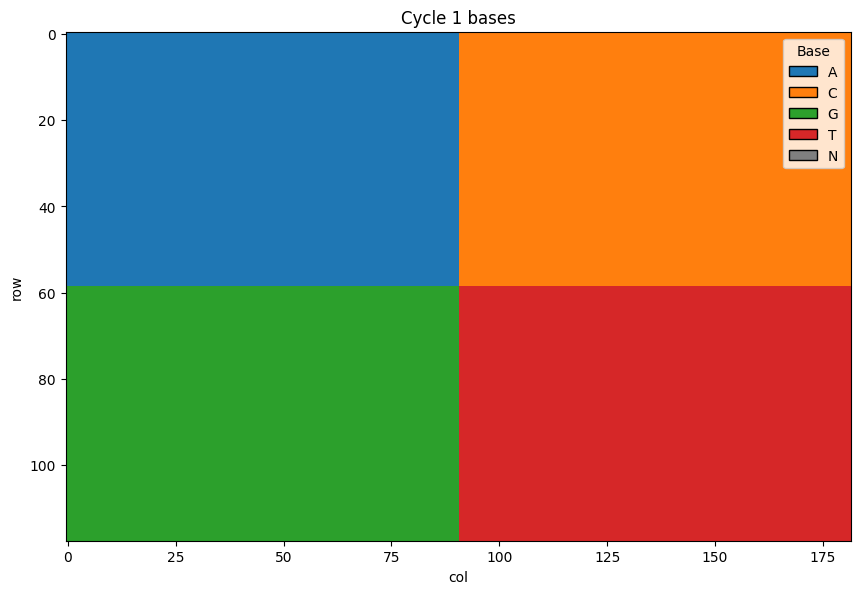

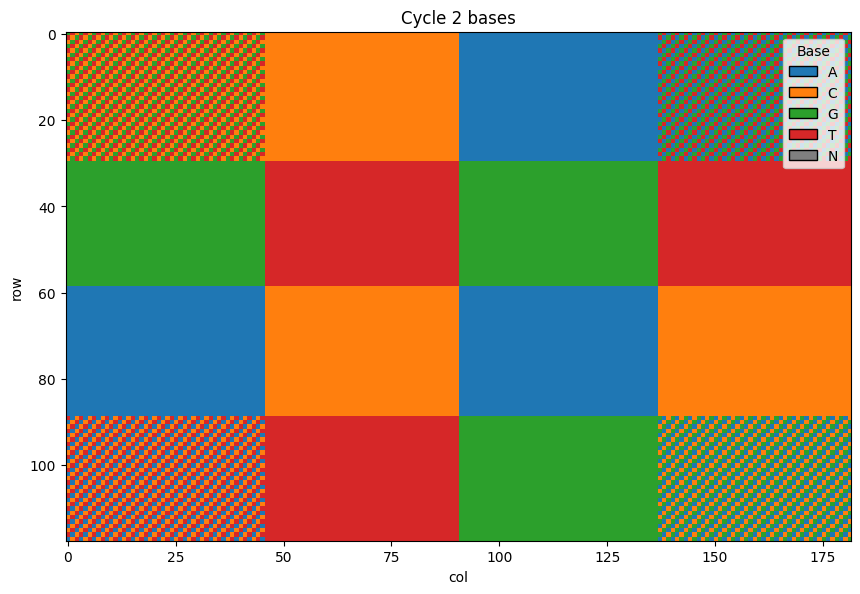

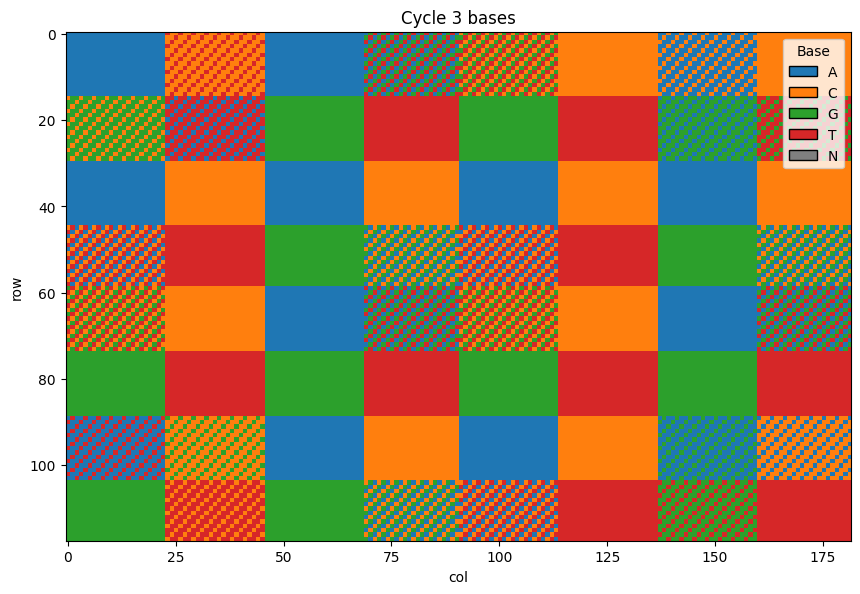

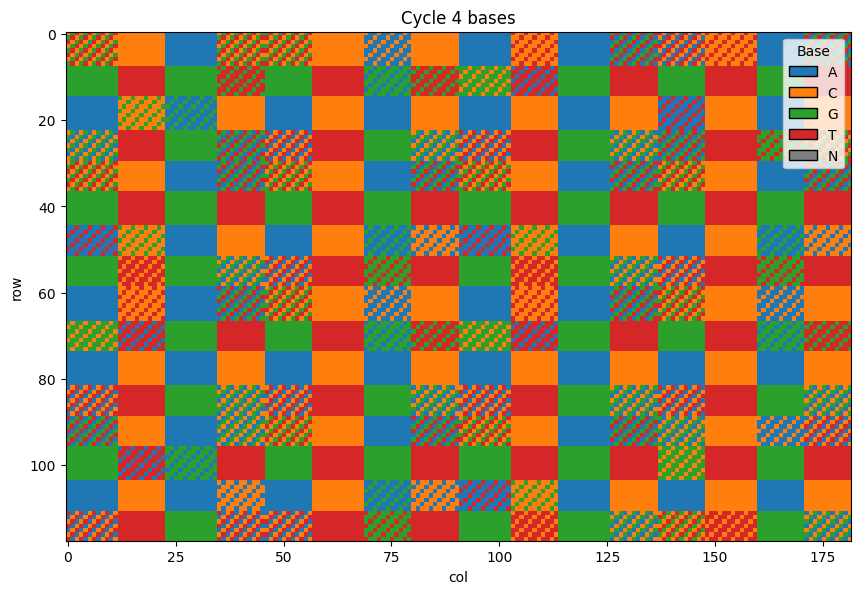

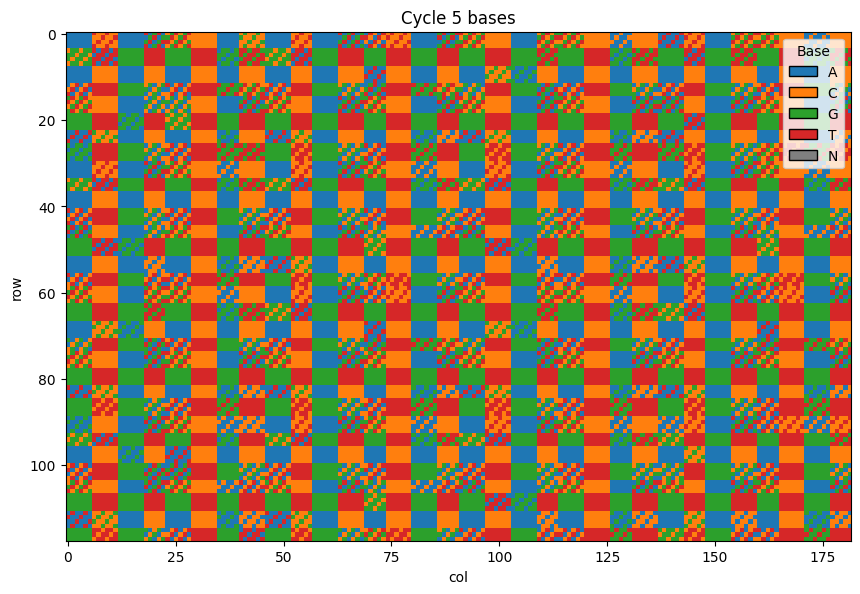

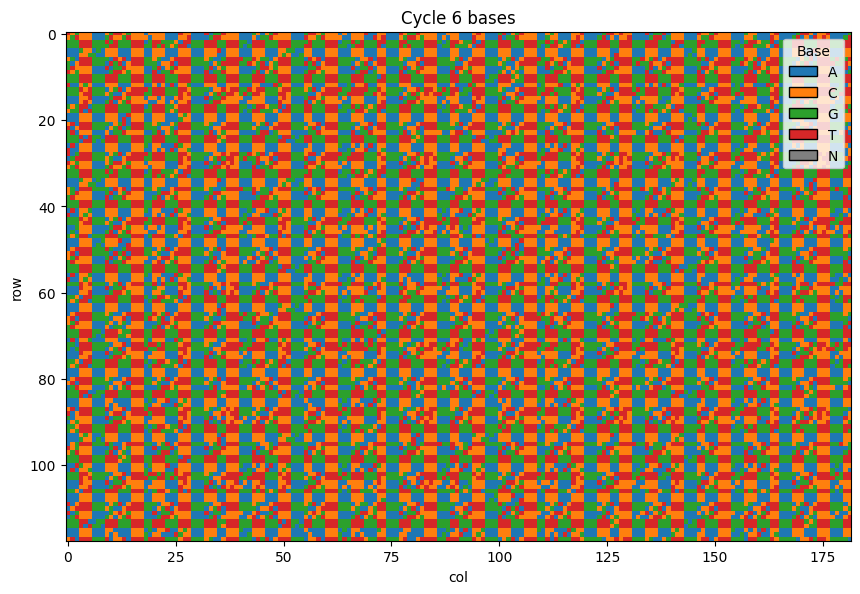

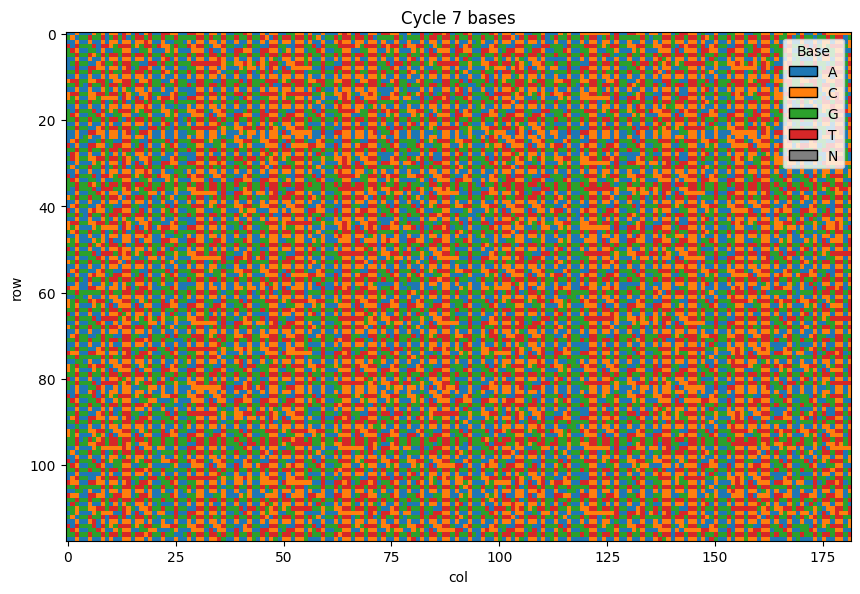

<Axes: title={'center': 'Cycle 7 bases'}, xlabel='col', ylabel='row'>

In [ ]:
# Using the df from your generator
df = res.df  # columns: row, col, idx, barcode

# Plot cycle 10 (1-based)
plot_cycle_bases(df, cycle=1, one_based=True, title="Cycle 1 bases", save_path="cycle1_bases.png")
plot_cycle_bases(df, cycle=2, one_based=True, title="Cycle 2 bases", save_path="cycle2_bases.png")
plot_cycle_bases(df, cycle=3, one_based=True, title="Cycle 3 bases", save_path="cycle3_bases.png")
plot_cycle_bases(df, cycle=4, one_based=True, title="Cycle 4 bases", save_path="cycle4_bases.png")
plot_cycle_bases(df, cycle=5, one_based=True, title="Cycle 5 bases", save_path="cycle5_bases.png")
plot_cycle_bases(df, cycle=6, one_based=True, title="Cycle 6 bases", save_path="cycle6_bases.png")
plot_cycle_bases(df, cycle=7, one_based=True, title="Cycle 7 bases", save_path="cycle7_bases.png")

# Plot cycle 0 (0-based) and save to file
# plot_cycle_bases(df, cycle=0, one_based=False, save_path="cycle0_bases.png")


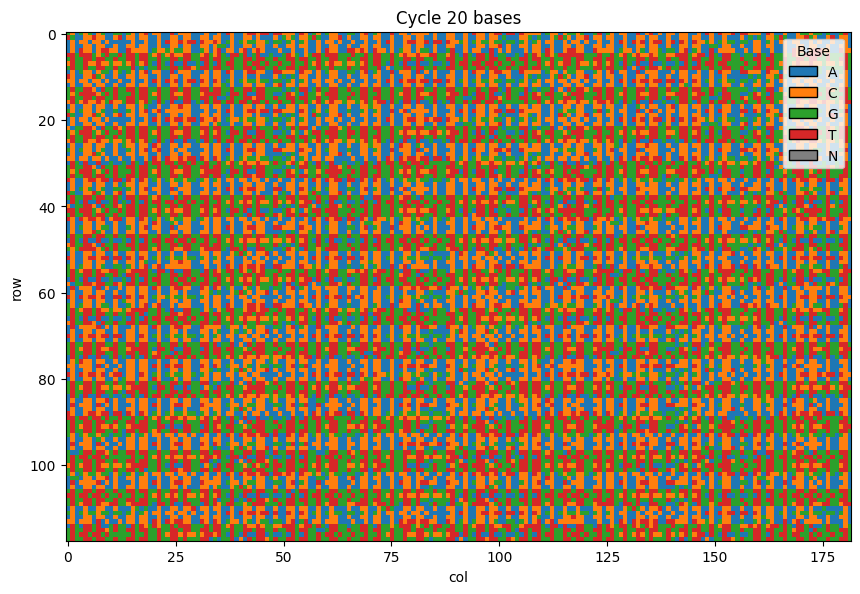

<Axes: title={'center': 'Cycle 20 bases'}, xlabel='col', ylabel='row'>

In [40]:
plot_cycle_bases(df, cycle=20, one_based=True, title="Cycle 20 bases", save_path="cycle20_bases.png")

In [33]:
import numpy as np
import pandas as pd
from pathlib import Path

def write_barcodes_column_major(df: pd.DataFrame,
                                out_path: str | Path,
                                *,
                                one_based_coords: bool = False,
                                expected_shape: tuple[int,int] | None = None,
                                strict: bool = True) -> None:
    """
    Save barcodes in column-major order to a text file (one per line).

    df must contain columns: 'row', 'col', 'barcode'
    - If one_based_coords=True, 'row' and 'col' are treated as 1-based.
    - If expected_shape=(R,C) is given, validate coverage against it.
    - If strict=True, error on missing/duplicate (row,col); else fill missing with 'N'*len(barcode).
    """
    required = {'row','col','barcode'}
    if not required.issubset(df.columns):
        raise ValueError(f"DataFrame must contain {required}")

    # Work on a copy of coords so we don't mutate the user's df
    rows = df['row'].to_numpy(dtype=int).copy()
    cols = df['col'].to_numpy(dtype=int).copy()
    if one_based_coords:
        rows -= 1
        cols -= 1

    # Grid size
    if expected_shape is not None:
        R, C = expected_shape
    else:
        R = int(rows.max()) + 1
        C = int(cols.max()) + 1

    # Validate coords in range
    if (rows < 0).any() or (rows >= R).any() or (cols < 0).any() or (cols >= C).any():
        raise ValueError("Found (row,col) outside inferred/expected grid dimensions")

    # Column-major linear index: i = col*R + row
    lin = cols * R + rows

    # Check duplicates / missing
    n = R * C
    uniq_lin, counts = np.unique(lin, return_counts=True)
    dups = uniq_lin[counts > 1]
    if strict and len(dups) > 0:
        # find which (row,col) are duplicated
        dup_rc = [(int(d % R), int(d // R)) for d in dups]
        raise ValueError(f"Duplicate (row,col) entries found at: {dup_rc}")

    # Build output array
    out = np.empty(n, dtype=object)
    out[:] = None
    out[lin] = df['barcode'].to_numpy()

    # Handle missing cells
    missing = np.where(pd.isna(out))[0]
    if len(missing) > 0:
        if strict:
            # report first few missing positions for debugging
            miss_rc = [(int(m % R), int(m // R)) for m in missing[:10]]
            raise ValueError(f"Missing barcodes for {len(missing)} positions; examples: {miss_rc}")
        else:
            # Fill with Ns of correct length
            L = len(str(df['barcode'].iloc[0]))
            out[missing] = "N" * L

    # Write file
    out_path = Path(out_path)
    out_path.write_text("\n".join(map(str, out)), encoding="utf-8")


# ---------- quick one-liner version (no strict checks) ----------
def write_barcodes_column_major_fast(df: pd.DataFrame, out_path: str | Path, *, one_based_coords: bool = False):
    tmp = df.copy()
    if one_based_coords:
        tmp['row'] = tmp['row'] - 1
        tmp['col'] = tmp['col'] - 1
    tmp.sort_values(['col','row'])['barcode'].to_csv(out_path, index=False, header=False)


In [34]:
# If your result object is `res` from the generator above:
df = res.df  # columns: row, col, idx, barcode

# Strict validation (recommended)
write_barcodes_column_major(df, "barcodes_col_major.txt")

# Or: fast path without grid-coverage checks
write_barcodes_column_major_fast(df, "barcodes_col_major_fast.txt")


In [42]:
res.df.head(n=50)

,row,col,idx,barcode
0,0,0,0,AGACATAGACATAGACATAGACATAGACATAGACAT
1,0,1,1,ATAGACACACACTACATAGCACACTACATAGCACAC
2,0,2,2,ACATAGCACACTACATAGCACACTACATAGCACACT
3,0,3,3,AGACACAGACTCGATAGCAGACTCGATAGCAGACTC
4,0,4,4,ATAGACACGACAGACATCACGACAGACATCACGACA
5,0,5,5,ACATACACATAGCAGACTCGATAGCAGACTCGATAG
6,0,6,6,AGACTACATCTCAGACTACATCTCAGACTACATCTC
7,0,7,7,ATAGCAGCGCACTACACAGCGCACTACACAGCGCAC
8,0,8,8,ACATCACGACAGACATCACGACAGACATCACGACAG
9,0,9,9,AGACTCAGCACACATACACACACACATACACACACA
